# Assignment 3: Federated Learning and Differential Privacy

Run all cells in order. Put the course `Assignment3-data.zip` next to this notebook. The full implementation is in `federated.py`. The functions below run the experiments and save their outputs. Test data are loaded only after the settings are selected using validation data.

## 1. Data and model

Each user is a client. Each client has its own 80/20 split. The network has two linear layers: 784 to 128, ReLU, and 128 to 62. Training uses one CPU thread per process.

In [1]:
from pathlib import Path
import json
import sys
import subprocess
import torch
from IPython.display import Image, display
from federated import load_clients, model
from run_experiments import (tune, select, ray_experiments, noise_experiments,
                             validations, final_test)

ROOT = Path.cwd()
assert (ROOT / "Assignment3-data.zip").exists(), "Use reports/ as the working directory"
torch.set_num_threads(1)
clients = load_clients(ROOT / "Assignment3-data.zip")
print(f"Clients: {len(clients)}")
print(f"Training images: {sum(len(c["y"]) for c in clients)}")
print(f"Validation images: {sum(len(c["vy"]) for c in clients)}")
print(model())

Clients: 100
Training images: 25418
Validation images: 6407
Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=128, bias=True)
  (2): ReLU()
  (3): Linear(in_features=128, out_features=62, bias=True)
)


## 2. Find better training settings

Compare the original pixels with `1 - pixels`, using matched initial weights and clients. Compare learning rates, then 100/200/300 rounds, then C=5%/10% and E=1/3/5. Choose by final validation accuracy. The C/E grid holds the number of communication rounds fixed; it does not hold the amount of local computation fixed.

In [2]:
tune(clients)
select(clients)
chosen = json.loads((ROOT / "selected_config.json").read_text())["chosen"]
print("Chosen setting:", chosen["config"])
print("Validation accuracy:", chosen["validation"]["accuracy"])

CACHED raw-lr0.01-c10-e3-r100-b0.0-s42


CACHED raw-lr0.03-c10-e3-r100-b0.0-s42


CACHED raw-lr0.1-c10-e3-r100-b0.0-s42


CACHED raw-lr0.3-c10-e3-r100-b0.0-s42


CACHED ink-lr0.01-c10-e3-r100-b0.0-s42


CACHED ink-lr0.03-c10-e3-r100-b0.0-s42


... (12 outputs left out)

CACHED ink-lr1.0-c10-e3-r300-b0.0-s42


CACHED ink-lr1.0-c10-e5-r300-b0.0-s42


FINAL CONFIG {"config": {"clients": 10, "epochs": 1, "lr": 1.0, "rounds": 300, "seed": 42, "inputs": "ink", "noise": 0.0}, "train": {"loss": 0.43344052937809513, "accuracy": 0.8712329844991739}, "validation": {"loss": 0.7378337896426531, "accuracy": 0.8122366162010302}, "run": "ink-lr1.0-c10-e1-r300-b0.0-s42-f3a31c46219d.json", "state": "ink-lr1.0-c10-e1-r300-b0.0-s42-f3a31c46219d.pt"}


Chosen setting: {'clients': 10, 'epochs': 1, 'lr': 1.0, 'rounds': 300, 'seed': 42, 'inputs': 'ink', 'noise': 0.0}
Validation accuracy: 0.8122366162010302


## 3. Four parallel clients with Ray Core

Create Actors only for the four clients selected in each round. Each Actor uses one CPU and one PyTorch thread. Compare the full run with serial execution under the same model, data, and seeds. Both weights and validation curves must match.

In [3]:
ray_experiments(clients)

/Users/Admin/miniconda3/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-11-17 13:19:01,702	INFO util.py:155 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


CACHED four-client-serial


CACHED four-client-ray


RAY MATCH {"config": {"clients": 4, "epochs": 1, "lr": 1.0, "rounds": 300, "seed": 42, "inputs": "ink", "noise": 0.0}, "serial_run": "four-client-serial-aba5274d9c6d.json", "parallel_run": "four-client-ray-382dae12ea93.json", "state": "four-client-ray-382dae12ea93.pt", "max_parameter_error": 0.0, "max_validation_curve_error": 0.0, "serial_update_seconds": 2.9405127086793073, "ray_update_seconds": 527.4340287520026, "cpus": 4}


## 4. Laplace input noise

Add independent Laplace noise once per training image. Keep it fixed during training and do not clip it. Evaluate training accuracy on these actual noisy inputs; also record clean-training accuracy. Validation stays clean. Repeat each scale with seeds 42, 43, and 44. Before test evaluation, choose the largest positive b whose mean validation accuracy is within two percentage points of b=0.

In [4]:
noise_experiments(clients)

CACHED ink-lr1.0-c10-e1-r300-b0.0-s42


CACHED ink-lr1.0-c10-e1-r300-b0.0-s43


CACHED ink-lr1.0-c10-e1-r300-b0.0-s44


CACHED ink-lr1.0-c10-e1-r300-b0.05-s42


CACHED ink-lr1.0-c10-e1-r300-b0.05-s43


CACHED ink-lr1.0-c10-e1-r300-b0.05-s44


... (6 outputs left out)

CACHED ink-lr1.0-c10-e1-r300-b0.6-s42


CACHED ink-lr1.0-c10-e1-r300-b0.6-s43


CACHED ink-lr1.0-c10-e1-r300-b0.6-s44


NOISE CHOICE {"means": {"0.0": 0.8040164403516986, "0.05": 0.7969928723791687, "0.1": 0.7828937100046823, "0.3": 0.6783205868581238, "0.6": 0.06805056968940221}, "choice": 0.05}


## 5. Validation and edge cases

Shuffle training labels within clients while preserving their label counts. Fit 16 known examples. Evaluate fixed-noise models on fresh noise draws. Check the single-client and zero-learning-rate limits, weighted averaging, and Laplace moments. Stress b=3 and record numerical failure if it occurs; also try a smaller rate. Finally, run four clients on a real one-CPU Ray cluster and inject an Actor failure after a previous batch succeeds. The global model must stay unchanged, resources must be released, and a full retry must match serial execution. One deliberate Ray error message is expected; this cell should still finish successfully.

In [5]:
validations(clients)

CACHED shuffled-label-control


STRONG NOISE {"config": {"clients": 10, "epochs": 1, "lr": 1.0, "rounds": 300, "seed": 42, "inputs": "ink", "noise": 3.0}, "source_sha256": "d2cc7fb59c5902ad54600ef2688bfa1130f571ce0cef27fe8a848de6202136fd", "status": "non_finite_update", "completed_rounds": 5, "failed_round": 6, "model_change_on_rejection": 0.0, "error": "A local update produced non-finite parameters", "last_finite_model_validation": {"loss": 4.4681803434149784e+32, "accuracy": 0.030747619790853754}, "outside_fraction": 0.8579207688268478}


CACHED strong-noise-lower-rate


VALIDATION {"split_overlap": 0, "single_client_error": 0.0, "zero_lr_error": 0.0, "unequal_client_counts": [275, 297], "aggregation_error": 1.4901161193847656e-08, "tiny_before": {"loss": 4.1038432121276855, "accuracy": 0.125}, "tiny_after": {"loss": 0.0008965732995420694, "accuracy": 1.0}, "shuffled_label_control": {"rounds": 100, "validation": {"loss": 3.718654269972662, "accuracy": 0.06508506321211176}, "real_label_validation": {"loss": 0.8877529503310435, "accuracy": 0.7607304510691432}, "run": "shuffled-label-control-1d3c15a0b67a.json"}, "zero_noise_parameter_error": 0.0, "fresh_noise_evaluation": {"0.0": {"stored_noise_accuracy": 0.8712329844991739, "fresh_noise_accuracy": 0.8712329844991739, "clean_train_accuracy": 0.8712329844991739}, "0.05": {"stored_noise_accuracy": 0.9047918797702416, "fresh_noise_accuracy": 0.8357463215044457, "clean_train_accuracy": 0.8556534739161225}, "0.1": {"stored_noise_accuracy": 0.9635691242426627, "fresh_noise_accuracy": 0.7518294122275553, "clean_

## 6. Held-out evaluation, figures, and report

The selected training settings and noise choice are now saved. Evaluate the held-out test data. Export all figures and numerical evidence, then rebuild the PDF. The test results do not feed back into selection.

FINAL TEST {"samples": 3621, "sequential": {"loss": 0.7568900422541617, "accuracy": 0.808064070698702}, "ray": {"loss": 0.8909036140684198, "accuracy": 0.7694007180336924}, "noise": {"0.0": {"loss": 0.7568900422541617, "accuracy": 0.808064070698702}, "0.05": {"loss": 0.8103069083132951, "accuracy": 0.80005523336095}, "0.1": {"loss": 0.889508385119666, "accuracy": 0.7892847279756974}, "0.3": {"loss": 1.4072281480065962, "accuracy": 0.6829605081469208}, "0.6": {"loss": 3.90824089482225, "accuracy": 0.06904170118751726}}, "chosen_noise": 0.05, "selection_frozen_before_test": true, "frozen_selection_sha256": "3e0427db46fad87eb10ae3409316a169657d55630583a8862cbe264146abd54f"}


{
  "test": {
    "samples": 3621,
    "sequential": {
      "loss": 0.7568900422541617,
      "accuracy": 0.808064070698702
    },
    "ray": {
      "loss": 0.8909036140684198,
      "accuracy": 0.7694007180336924
    },
    "noise": {
      "0.0": {
        "loss": 0.7568900422541617,
        "accuracy": 0.808064070698702
      },
      "0.05": {
        "loss": 0.8103069083132951,
        "accuracy": 0.80005523336095
      },
      "0.1": {
        "loss": 0.889508385119666,
        "accuracy": 0.7892847279756974
      },
      "0.3": {
        "loss": 1.4072281480065962,
        "accuracy": 0.6829605081469208
      },
      "0.6": {
        "loss": 3.90824089482225,
        "accuracy": 0.06904170118751726
      }
    },
    "chosen_noise": 0.05,
    "selection_frozen_before_test": true,
    "frozen_selection_sha256": "3e0427db46fad87eb10ae3409316a169657d55630583a8862cbe264146abd54f"
  },
  "client_summary": {
    "baseline_wins": 100,
    "accuracy_mean": 0.803150383917574,
    "a

/Users/Admin/Documents/ChatGPT/学还是得上啊/04-MLDS-490-IEMS-469/hw3/reports/Assignment3_Report.pdf


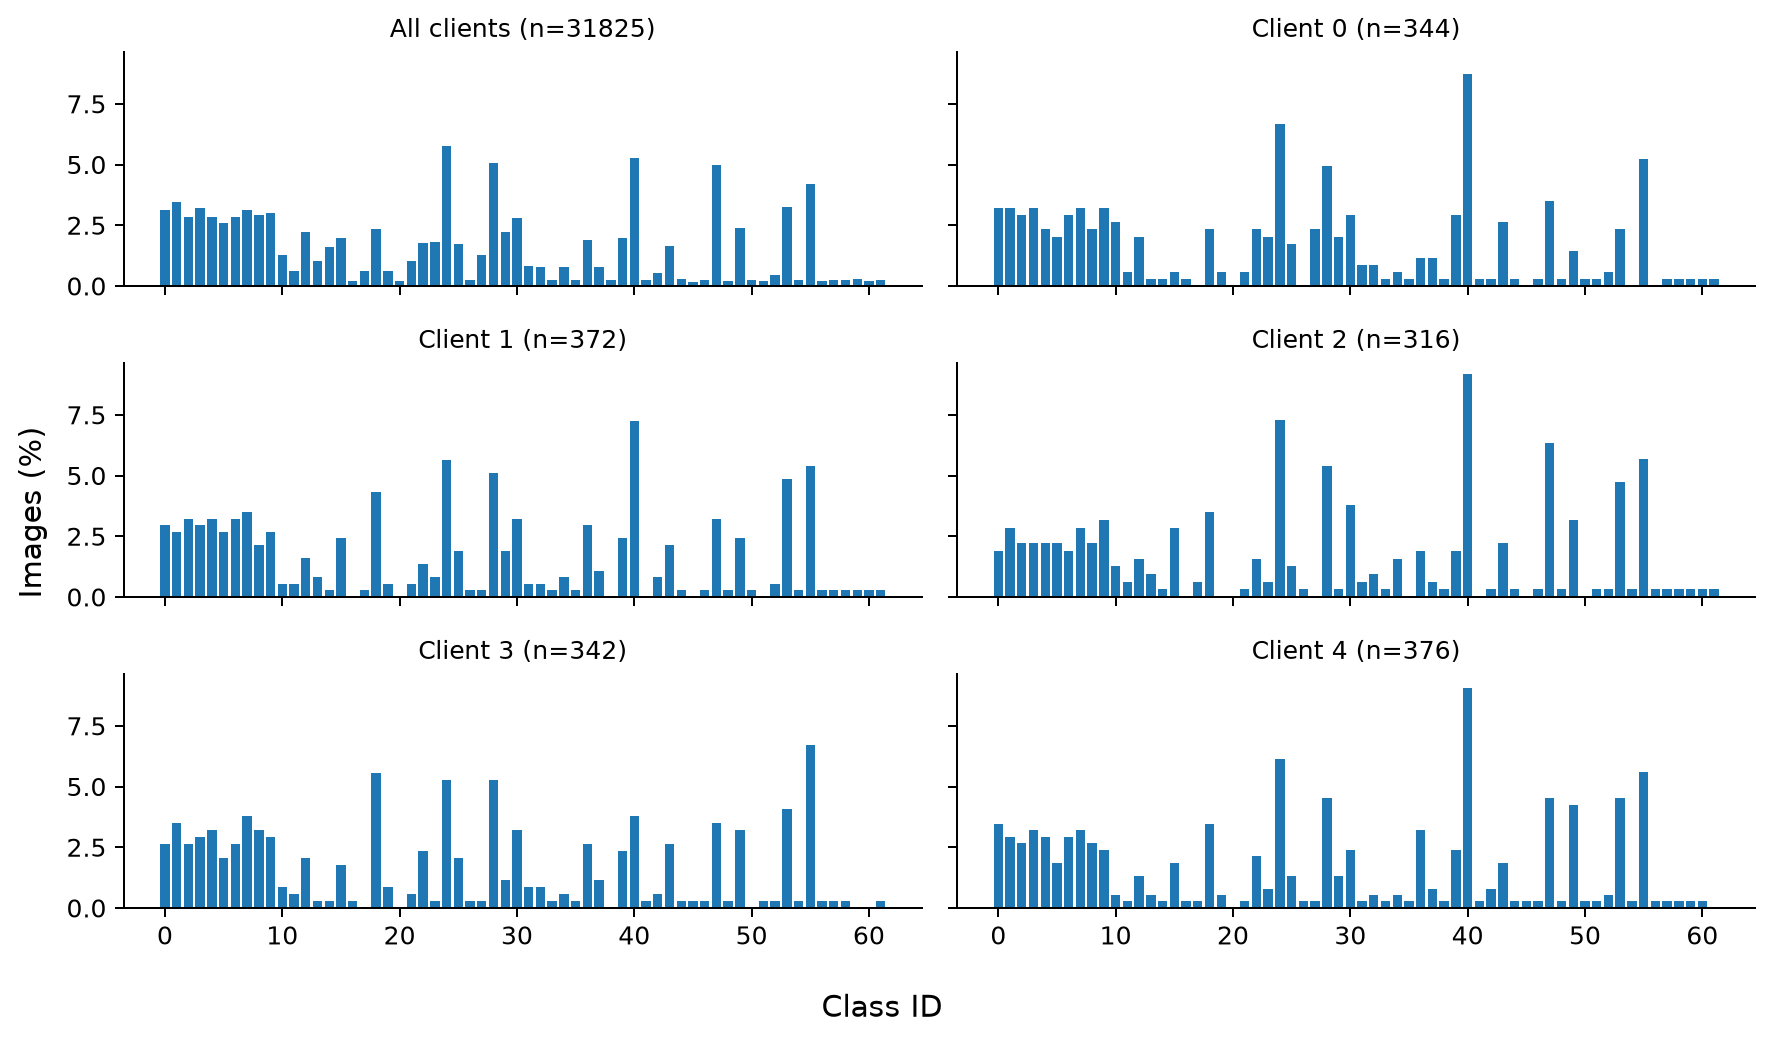

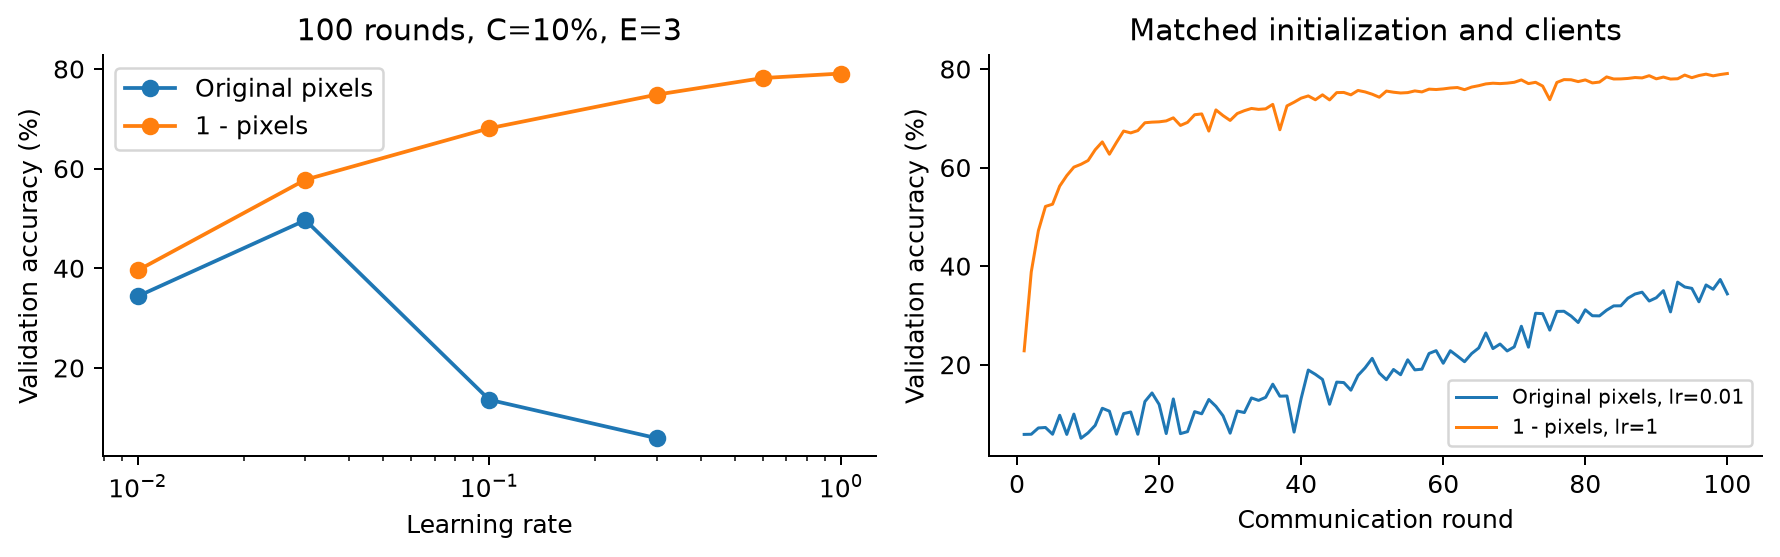

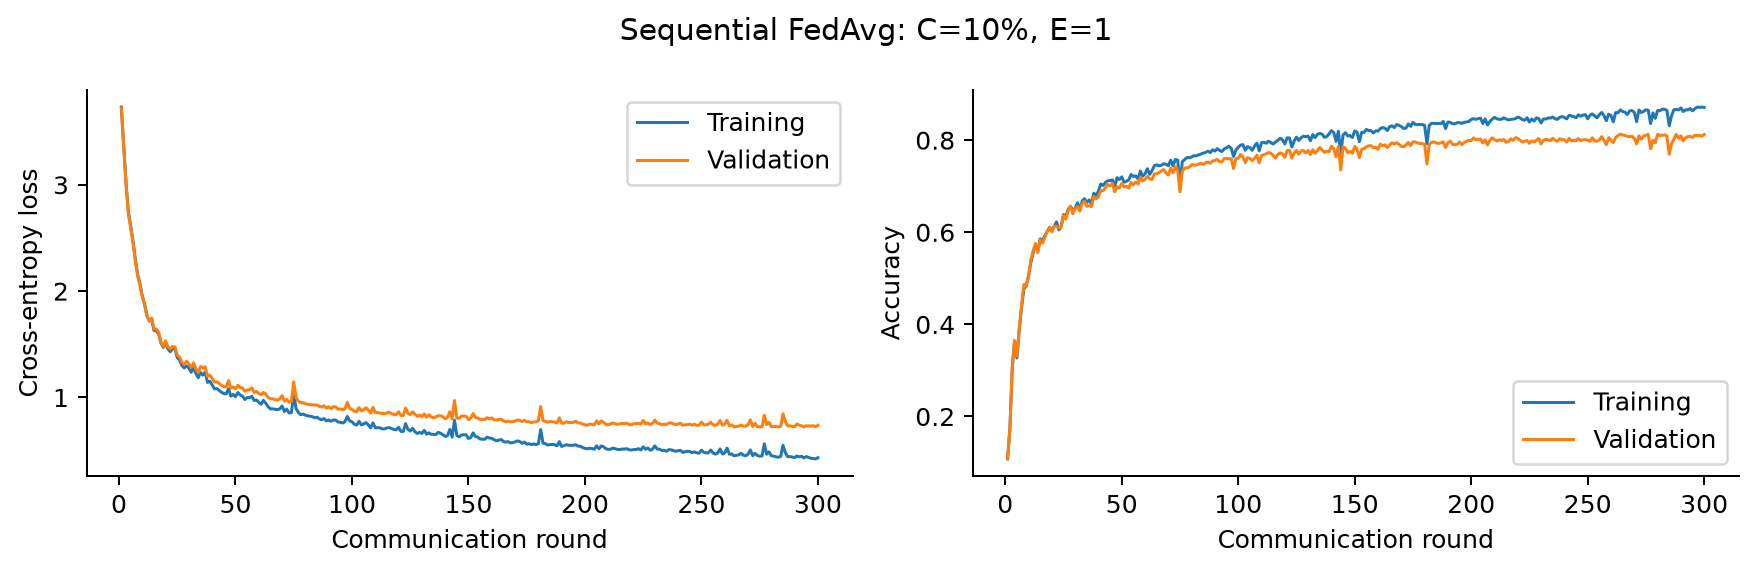

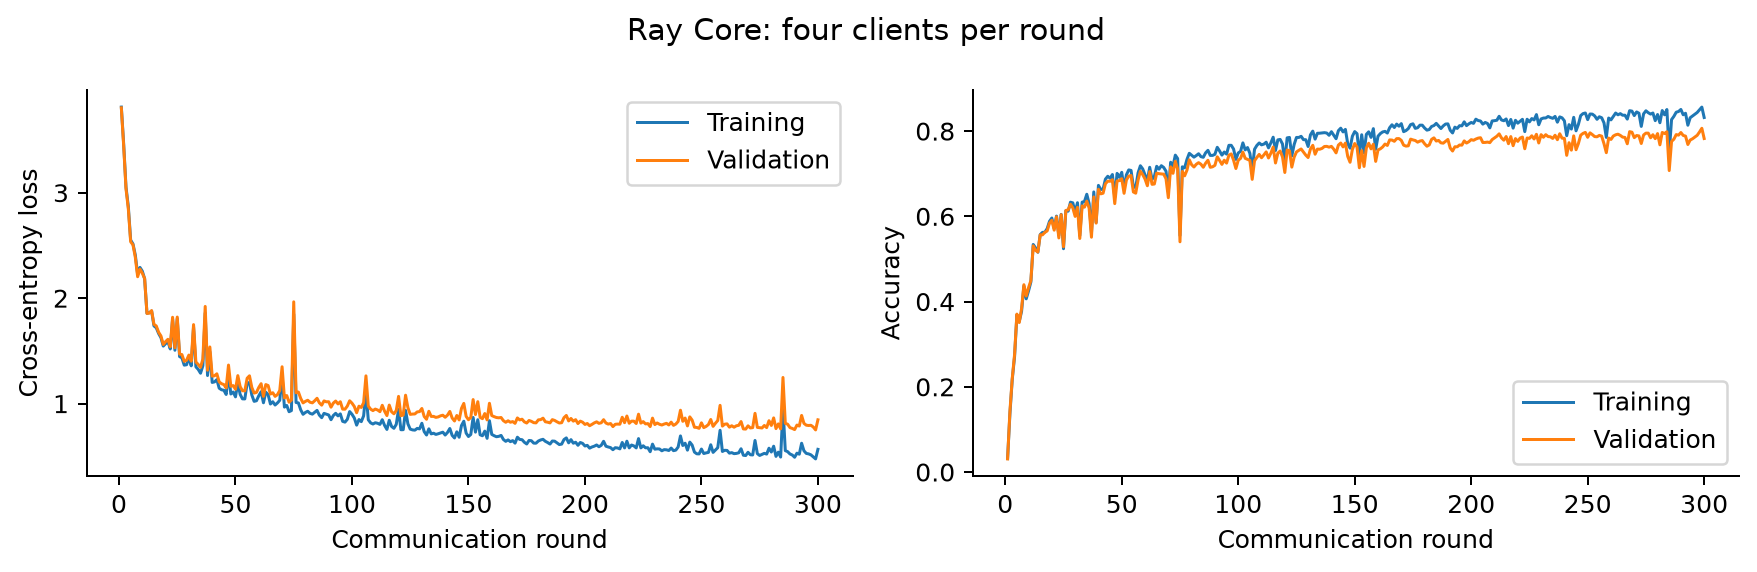

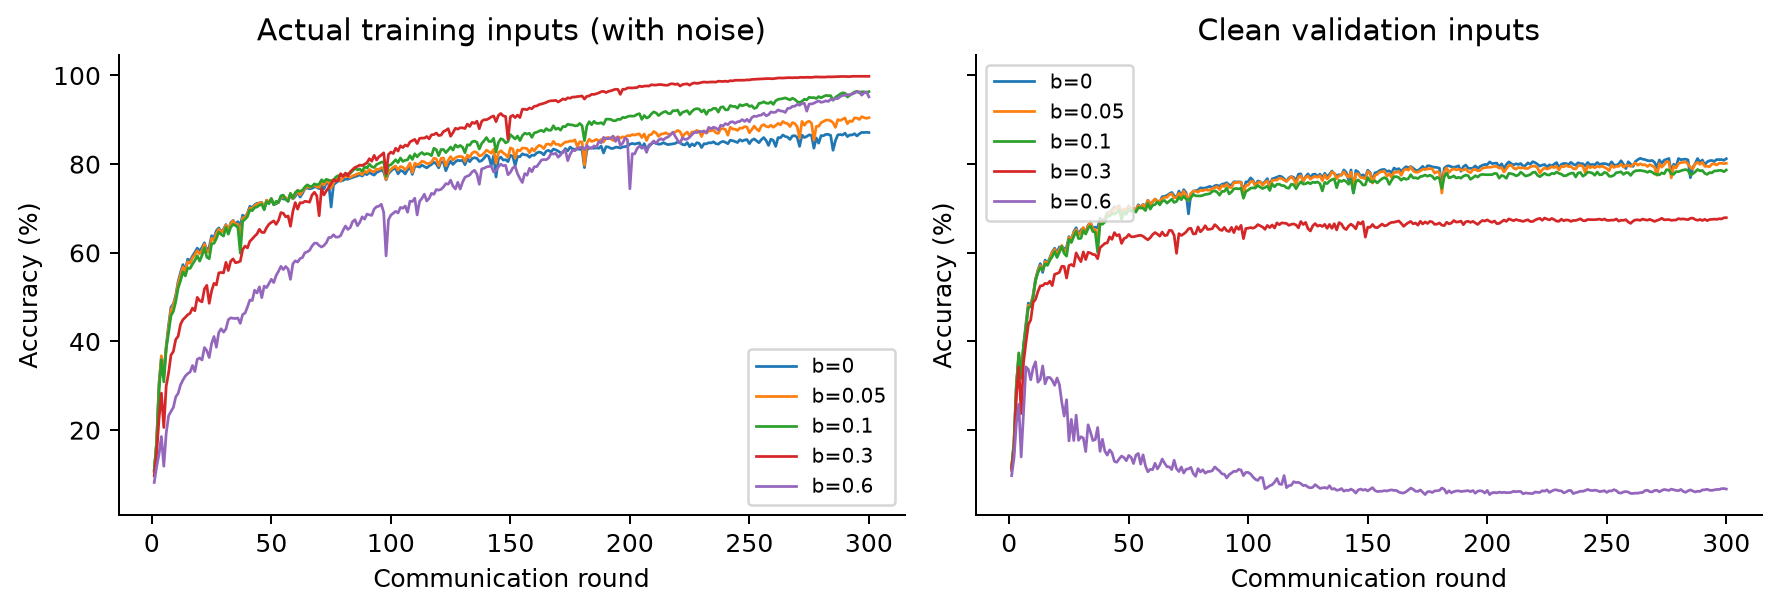

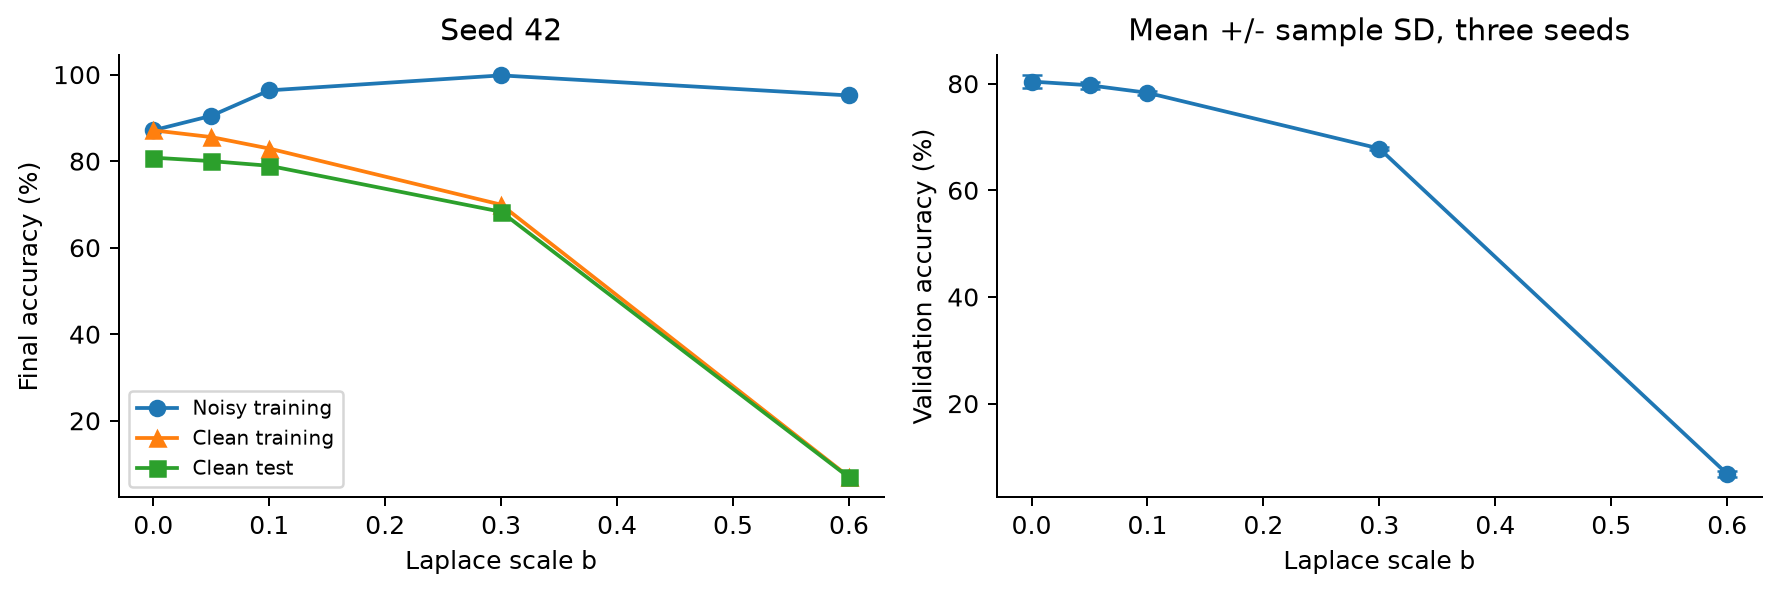

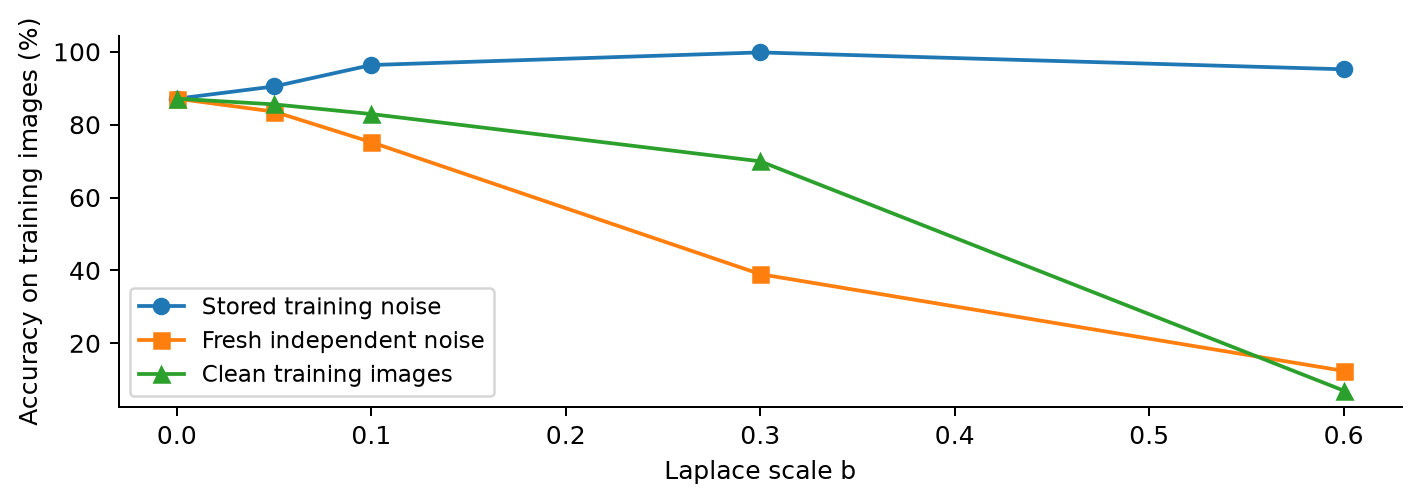

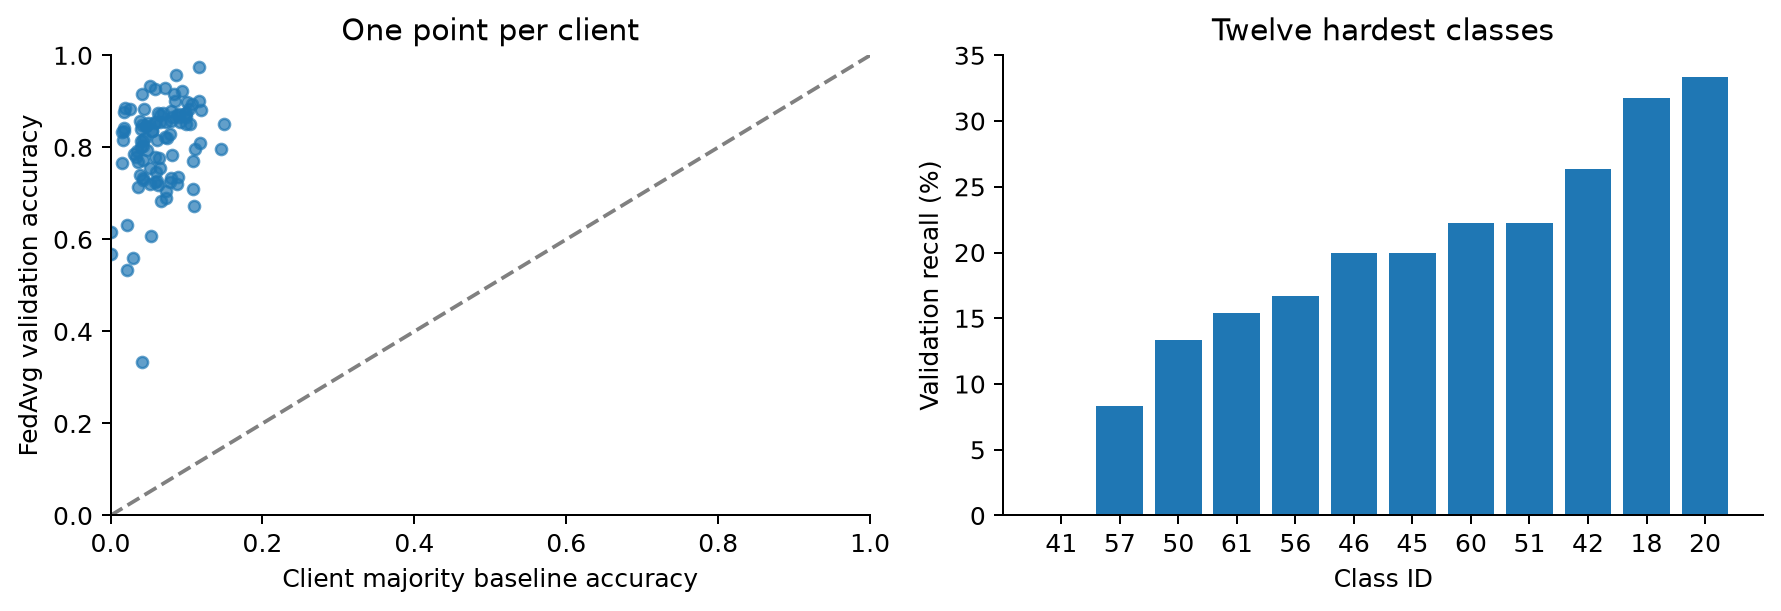

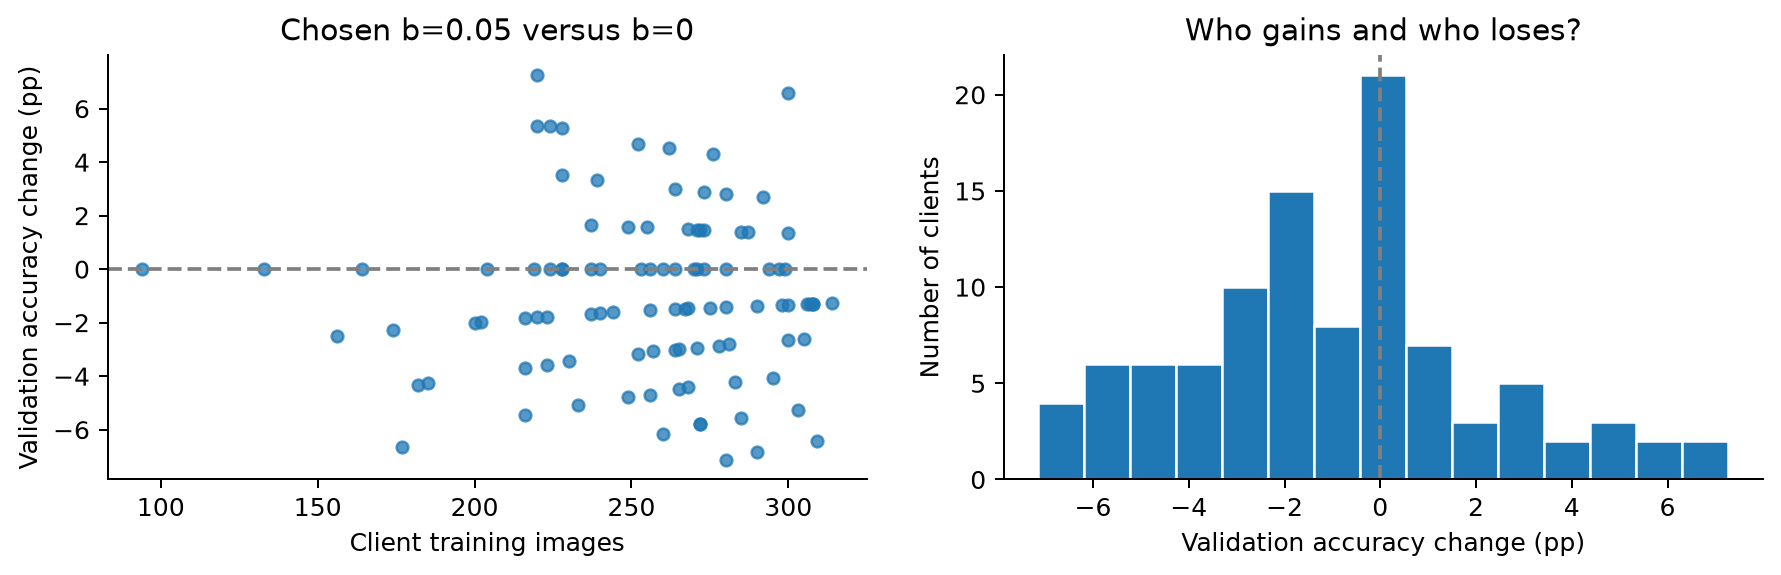

In [6]:
final_test(clients)
from make_figures import main as make_figures
make_figures()
subprocess.run([sys.executable, str(ROOT / "build_report.py")], check=True)
for name in ["class_distribution.png", "optimization_diagnosis.png",
             "sequential_curves.png", "ray_curves.png", "noise_round_curves.png",
             "noise_final_accuracy.png", "fresh_noise_check.png",
             "client_baseline.png", "noise_client_effect.png"]:
    display(Image(filename=str(ROOT / "figures" / name)))

The report explains the results and the experiments I would run with three more months. Each run is stored in `runs/`; the report reads `experiment_results.json`. A fresh clone has no model checkpoints, so it retrains. Repeating a completed run locally reuses a checkpoint only when its algorithm source and configuration match.